In [1]:
import numpy as np
print(np.__version__)

2.5.5


In [2]:
import pandas as pd 
print(pd.__version__)

3.1.1


In [3]:
import matplotlib

In [4]:
import matplotlib.pyplot as plt
print(matplotlib.__version__)

3.11.2


In [10]:
DF = pd.read_csv("bike_rent.csv")
print(DF)

    day  temperature  rentals
0     1           22       18
1     2           24       20
2     3           23       22
3     4           25       23
4     5           26       24
5     6           27       25
6     7           25       26
7     8           28       27
8     9           29       28
9    10           27       30
10   11           26       31
11   12           30       32
12   13           31       35
13   14           29      120


In [11]:
df = DF.copy()

In [12]:
print(df)

    day  temperature  rentals
0     1           22       18
1     2           24       20
2     3           23       22
3     4           25       23
4     5           26       24
5     6           27       25
6     7           25       26
7     8           28       27
8     9           29       28
9    10           27       30
10   11           26       31
11   12           30       32
12   13           31       35
13   14           29      120


In [14]:
print(df.head(3))

   day  temperature  rentals
0    1           22       18
1    2           24       20
2    3           23       22


In [15]:
print(df.dtypes)

day            int64
temperature    int64
rentals        int64
dtype: object


In [16]:
print(df.describe())

           day  temperature     rentals
count  14.0000    14.000000   14.000000
mean    7.5000    26.571429   32.928571
std     4.1833     2.651974   25.505548
min     1.0000    22.000000   18.000000
25%     4.2500    25.000000   23.250000
50%     7.5000    26.500000   26.500000
75%    10.7500    28.750000   30.750000
max    14.0000    31.000000  120.000000


In [17]:
print(df.isnull().sum())

day            0
temperature    0
rentals        0
dtype: int64


In [18]:
print(df.duplicated())

0     False
1     False
2     False
3     False
4     False
5     False
6     False
7     False
8     False
9     False
10    False
11    False
12    False
13    False
dtype: bool


In [19]:
array = df["rentals"].to_numpy()
print(array)

[ 18  20  22  23  24  25  26  27  28  30  31  32  35 120]


In [22]:
rent_avg = round(np.mean(array),2)

In [23]:
print(rent_avg)

32.93


In [24]:
rent_median = np.median(array)
print(rent_median)

26.5


In [26]:
rent_std = round(np.std(array),2)
print(rent_std)

24.58


In [27]:
Q1 = np.percentile(array , 25)
print(Q1)

23.25


In [28]:
Q3 = np.percentile(array , 75)
print(Q3)

30.75


In [29]:
IQR = Q3 - Q1
print(IQR)

7.5


In [30]:
L1 = Q1 - 1.5*IQR
print(L1)

12.0


In [31]:
L2 = Q3 + 1.5*IQR
print(L2)

42.0


In [36]:
outliers = df[(df["rentals"] < L1)|(df["rentals"] > L2)]
print(outliers)

    day  temperature  rentals
13   14           29      120


In [39]:
cleaned_df = df.loc[~((df["rentals"] < L1)| (df["rentals"] > L2))]
print(cleaned_df)

    day  temperature  rentals
0     1           22       18
1     2           24       20
2     3           23       22
3     4           25       23
4     5           26       24
5     6           27       25
6     7           25       26
7     8           28       27
8     9           29       28
9    10           27       30
10   11           26       31
11   12           30       32
12   13           31       35


In [59]:
print("Before dataset:")
print(df)
print("Mean: ",rent_avg)
print("Standard deviation: ", rent_std)
print("Median: ",rent_median)
print("Q1: " , Q1)
print("Q2: " , Q3)
print("Lower boundary: ",L1)
print("Upper boundary" , L2)
print("IQR: ", IQR)


Before dataset:
    day  temperature  rentals
0     1           22       18
1     2           24       20
2     3           23       22
3     4           25       23
4     5           26       24
5     6           27       25
6     7           25       26
7     8           28       27
8     9           29       28
9    10           27       30
10   11           26       31
11   12           30       32
12   13           31       35
13   14           29      120
Mean:  32.93
Standard deviation:  24.58
Median:  26.5
Q1:  23.25
Q2:  30.75
Lower boundary:  12.0
Upper boundary 42.0
IQR:  7.5


In [61]:
print("After cleaning dataset:")
print(cleaned_df)
cleaned_array = cleaned_df["rentals"].to_numpy()
mean_cleaned = round(np.mean(cleaned_array),2)
std_cleaned = round(np.std(cleaned_array),2)
median_cleaned = np.median(cleaned_array)
C_Q1 = np.percentile(cleaned_array , 25)
C_Q3 = np.percentile(cleaned_array , 75)
C_IQR = C_Q3 - C_Q1
C_L1 = C_Q1 - 1.5*IQR
C_L3 = C_Q3 + 1.5*IQR
print("Mean: ",mean_cleaned)
print("Standard deviation: ",std_cleaned)
print("Median: ",median_cleaned)
print("Q1: ",C_Q1)
print("Q3: ",C_Q3)
print("Lower boundary: ",C_L1)
print("Upper boundary: ",C_L3)
print("IQR: ",C_IQR)


After cleaning dataset:
    day  temperature  rentals
0     1           22       18
1     2           24       20
2     3           23       22
3     4           25       23
4     5           26       24
5     6           27       25
6     7           25       26
7     8           28       27
8     9           29       28
9    10           27       30
10   11           26       31
11   12           30       32
12   13           31       35
Mean:  26.23
Standard deviation:  4.74
Median:  26.0
Q1:  23.0
Q3:  30.0
Lower boundary:  11.75
Upper boundary:  41.25
IQR:  7.0


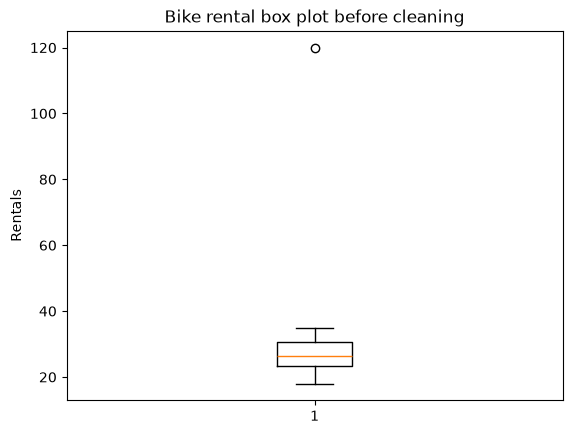

In [58]:
plt.boxplot(df["rentals"])
plt.title("Bike rental box plot before cleaning")
plt.ylabel("Rentals")
plt.show()

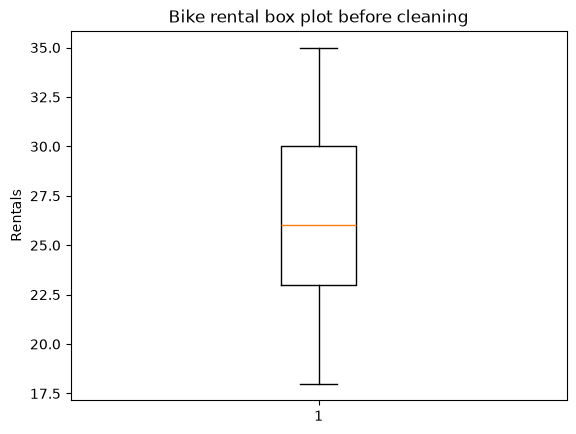

In [60]:
plt.boxplot(cleaned_df["rentals"])
plt.ylabel("Rentals")
plt.title("Bike rental box plot before cleaning")
plt.show()